1. Load the data

In [22]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("iris.csv")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


2. Inspect the data

In [23]:
print(df.shape)
print(df.columns.tolist())
df.info()

(150, 5)
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [24]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nRows per species:")
print(df["species"].value_counts())

Missing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Duplicate rows: 1

Rows per species:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [25]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


3. Pairplot

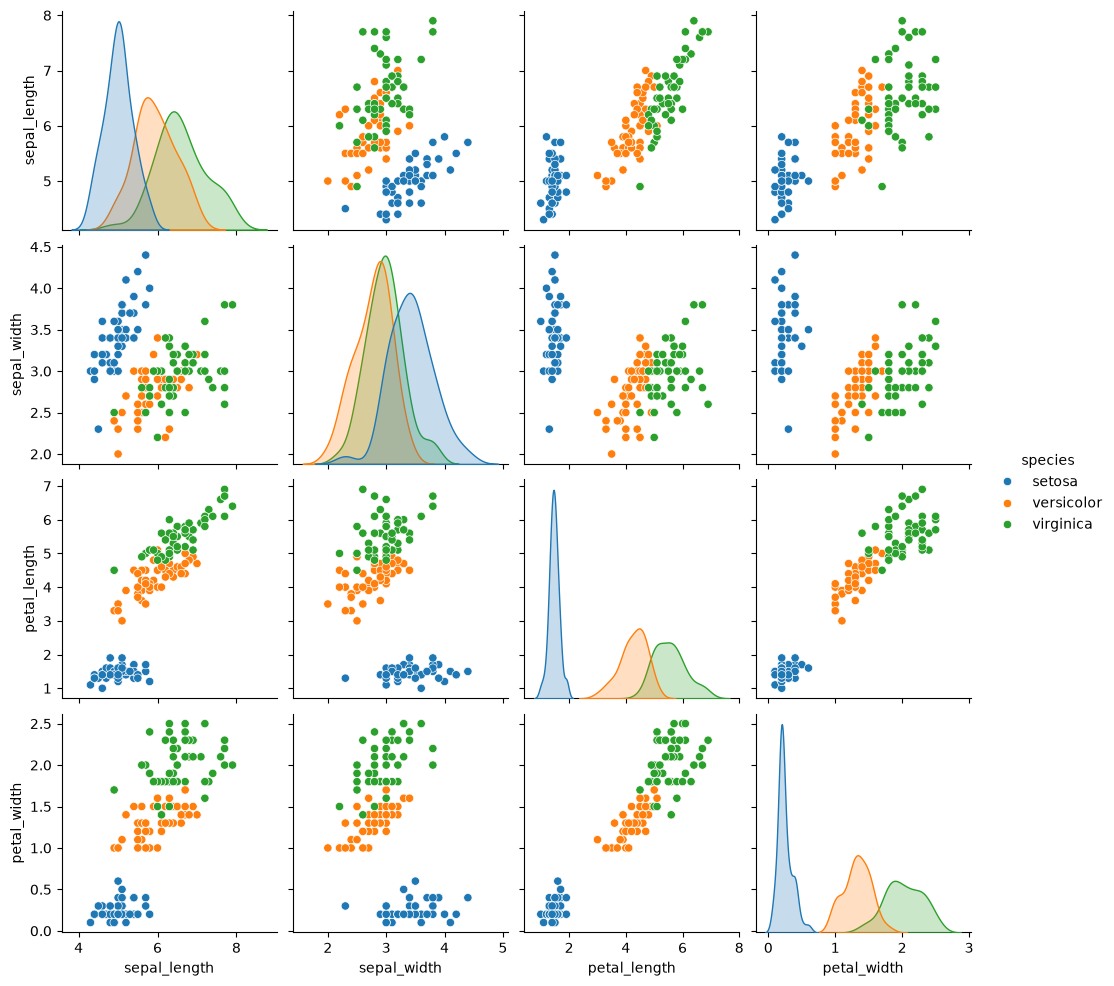

In [26]:
sns.pairplot(df, hue="species")
plt.show()

Setosa is clearly separated. Versicolor and virginica overlap each other, so I expect the models to confuse those two.

4. Features and target

In [27]:
X = df.drop(columns="species")
y = df["species"]

print(X.shape, y.shape)
X.head()

(150, 4) (150,)


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [28]:
y.head()

0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: str

5. Split into test and train(80/20)

In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

X_train: (120, 4)
X_test:  (30, 4)
y_train: (120,)
y_test:  (30,)


In [30]:
print("Train species counts:")
print(y_train.value_counts())
print("\nTest species counts:")
print(y_test.value_counts())

Train species counts:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Test species counts:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


6. Scale the features with standardscaler

In [31]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [32]:
print("Train mean:", np.round(X_train_scaled.mean(axis=0), 2))
print("Train std: ", np.round(X_train_scaled.std(axis=0), 2))
print("Test mean: ", np.round(X_test_scaled.mean(axis=0), 2))
print("Test std:  ", np.round(X_test_scaled.std(axis=0), 2))

Train mean: [-0.  0.  0.  0.]
Train std:  [1. 1. 1. 1.]
Test mean:  [ 0.01  0.1  -0.03 -0.04]
Test std:   [0.93 0.85 0.99 1.  ]


7. Model training

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

log_reg = LogisticRegression(max_iter=1000)
tree = DecisionTreeClassifier(random_state=42)

log_reg.fit(X_train_scaled, y_train)
tree.fit(X_train_scaled, y_train)

print(log_reg)
print(tree)

LogisticRegression(max_iter=1000)
DecisionTreeClassifier(random_state=42)


In [34]:
print("Logistic Regression train accuracy:", round(log_reg.score(X_train_scaled, y_train), 4))
print("Decision Tree train accuracy:      ", round(tree.score(X_train_scaled, y_train), 4))

Logistic Regression train accuracy: 0.9583
Decision Tree train accuracy:       1.0


8. Prediction and metrics

In [35]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report
)

y_pred_lr = log_reg.predict(X_test_scaled)
y_pred_tree = tree.predict(X_test_scaled)

In [36]:
print("---Logistic Regression ---")
print(classification_report(y_test, y_pred_lr))

---Logistic Regression ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [37]:
print("---Decision Tree ---")
print(classification_report(y_test, y_pred_tree))

---Decision Tree ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [38]:
for name, preds in [("Logistic Regression", y_pred_lr), ("Decision Tree", y_pred_tree)]:
    print(name)
    print("  Accuracy :", round(accuracy_score(y_test, preds), 4))
    print("  Precision:", round(precision_score(y_test, preds, average="macro"), 4))
    print("  Recall   :", round(recall_score(y_test, preds, average="macro"), 4))
    print("  F1-score :", round(f1_score(y_test, preds, average="macro"), 4))
    print()

Logistic Regression
  Accuracy : 0.9333
  Precision: 0.9333
  Recall   : 0.9333
  F1-score : 0.9333

Decision Tree
  Accuracy : 0.9333
  Precision: 0.9333
  Recall   : 0.9333
  F1-score : 0.9333



9.Benchmark table

In [39]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Correct (of 30)": [
        (y_test.values == y_pred_lr).sum(),
        (y_test.values == y_pred_tree).sum()
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_tree)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr, average="macro"),
        precision_score(y_test, y_pred_tree, average="macro")
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr, average="macro"),
        recall_score(y_test, y_pred_tree, average="macro")
    ],
    "F1-score": [
        f1_score(y_test, y_pred_lr, average="macro"),
        f1_score(y_test, y_pred_tree, average="macro")
    ],
}).set_index("Model").round(4)

results

,Correct (of 30),Accuracy,Precision,Recall,F1-score
Model,,,,,
Logistic Regression,28,0.9333,0.9333,0.9333,0.9333
Decision Tree,28,0.9333,0.9333,0.9333,0.9333


10.Confusion metrics

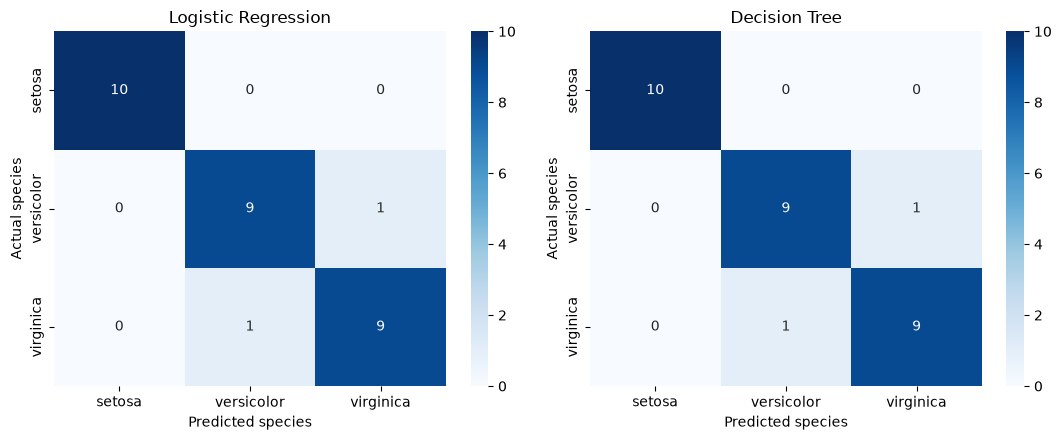

In [40]:
from sklearn.metrics import confusion_matrix

labels = ["setosa", "versicolor", "virginica"]

cm_lr = confusion_matrix(y_test, y_pred_lr, labels=labels)
cm_tree = confusion_matrix(y_test, y_pred_tree, labels=labels)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, cm, title in [
    (axes[0], cm_lr, "Logistic Regression"),
    (axes[1], cm_tree, "Decision Tree"),
]:
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Predicted species")
    ax.set_ylabel("Actual species")

plt.tight_layout()
plt.show()

11.Decision boundary plot

In [41]:
features_2d = ["petal_length", "petal_width"]

scaler_2d = StandardScaler()
X_train_2d = scaler_2d.fit_transform(X_train[features_2d])
X_test_2d = scaler_2d.transform(X_test[features_2d])

lr_2d = LogisticRegression(max_iter=1000).fit(X_train_2d, y_train)
tree_2d = DecisionTreeClassifier(random_state=42).fit(X_train_2d, y_train)

print("Logistic Regression (2 features) test accuracy:", round(lr_2d.score(X_test_2d, y_test), 4))
print("Decision Tree (2 features) test accuracy:      ", round(tree_2d.score(X_test_2d, y_test), 4))

Logistic Regression (2 features) test accuracy: 0.9333
Decision Tree (2 features) test accuracy:       0.9333


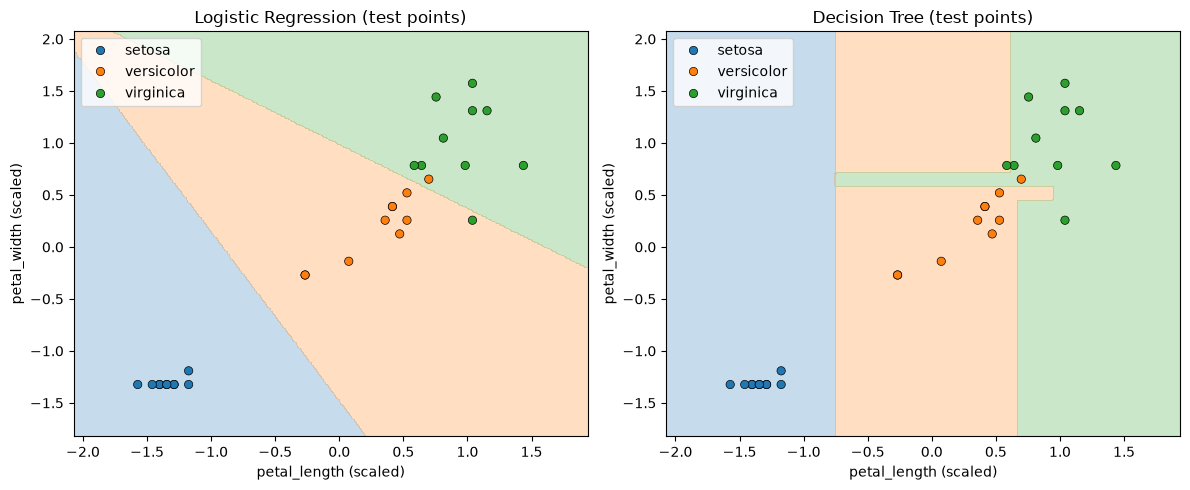

In [42]:
labels = ["setosa", "versicolor", "virginica"]
class_to_num = {name: i for i, name in enumerate(labels)}
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

def plot_boundary(model, X_2d, y_true, title, ax):
    x_min, x_max = X_2d[:, 0].min() - 0.5, X_2d[:, 0].max() + 0.5
    y_min, y_max = X_2d[:, 1].min() - 0.5, X_2d[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = pd.Series(model.predict(grid)).map(class_to_num).to_numpy().reshape(xx.shape)

    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5, 2.5], colors=colors, alpha=0.25)
    sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=y_true.to_numpy(),
                    hue_order=labels, palette=colors, edgecolor="black", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("petal_length (scaled)")
    ax.set_ylabel("petal_width (scaled)")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_boundary(lr_2d, X_test_2d, y_test, "Logistic Regression (test points)", axes[0])
plot_boundary(tree_2d, X_test_2d, y_test, "Decision Tree (test points)", axes[1])
plt.tight_layout()
plt.show()

12. Conclusion

- This Iris dataset has 150 rows,4 numeric features and 3 balanced species
  (50 each), with no missing values. One duplicate row was kept.
- I split the data 80/20  and fitted StandardScaler on the
  training data (only), to avoid data leakage.
- For the Logistic Regression and Decision Tree, both scored 0.9333 on accuracy,
  precision, recall and F1 (macro), with 28 of 30 test flowers correct.
- Setosa was classified perfectly. The only 2 with errors were one versicolor
  predicted as virginica and one virginica predicted as versicolor, which
  matches the overlap seen in the pairplot.
- The Decision Tree scored 1.0 on training data but 0.9333 on test data,
  a sign of overadapted. Its decision boundary is boxy and has a thin
  strip carved around individual points, whereas Logistic Regression
  draws smooth linear boundaries.
- The limitation is that with only 30 test rows, the two models cannot be reliably
  separated. Cross-validation would give a more accurate comparison.